Бизнес задача: Оценка изменения мощности ГТУ после модернизации осевого компрессора

Есть исходная таблица с показаниями датчиков САУ ГТУ.
Найти приведенную мощность ГТУ. Руководство хочет узнать как бы изменилась приведенная мощность после проведения модернизации лопаточного аппарата компрессора, которая увеличила КПД компрессора на 1,5 % .

1. Подготовка исходных данных

1.1. Подготовка исходной таблицы

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

# 1.1.1. Читаем исходный файл
df = pd.read_csv('gt_data.csv', sep = ';', skiprows = 3, header = None) # удаляем первые 3 строки, разделитель ";", без заголовка

# 1.1.2. Переименовываем столбцы
df.columns = ['DATE','GT SPEED','IGV POSITION','FUEL GAS CALORIE METER CALORIE (LHV)','FUEL GAS PILOT FLOW','FUEL GAS MAIN A CONTROL VALVE GAS FLOW','FUEL GAS MAIN B CONTROL VALVE GAS FLOW','FUEL GAS TOPHAT CONTROL VALVE GAS FLOW',
'AMBIENT TEMPERATURE','BAROMETRIC PRESS','AMBIENT HUMIDITY','INLET FILTER INSIDE PRESSURE','COMPRESSOR INLET AIR TEMPERATURE','COMBUSTOR SHELL PRESSURE','COMPRESSOR OUTLET AIR TEMPERATURE','EXHAUST GAS DUCT PRESSURE','GT POWER']

# 1.1.3. Просуммируем столбцы с расходом газа
cols_to_sum = ['FUEL GAS PILOT FLOW','FUEL GAS MAIN A CONTROL VALVE GAS FLOW',
               'FUEL GAS MAIN B CONTROL VALVE GAS FLOW','FUEL GAS TOPHAT CONTROL VALVE GAS FLOW'] # столбцы, которые необходимо просуммировать
df['TOTAL FUEL FLOW'] = df[cols_to_sum].sum(axis = 1)                                             # создаем новый столбец с суммой. (axis=1) - сложить по строке, в рамках одной строки
df=df.drop(columns = cols_to_sum)                                                                 # удаляем старые 4 столбца

# 1.1.4. Первая колонка - строка. Превращаем ее в дату 
df['DATE'] = pd.to_datetime(df['DATE'], format = '%d.%m.%Y %H:%M')

# 1.1.5. Превращаем текстовые столбцы в числа. Заменяем запятую на точку
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '.'), errors = 'coerce')    # заменяем запятые на точки и принудительно делаем числом (ошибки превращаем в NaN)

# 1.1.6. Смотрим что получилось
print("Размер таблицы (строки, столбцы):", df.shape)
print("\nТипы данных в столбцах:")
print(df.dtypes)

print("\nКол-во пропусков:")
print(df.isna().sum())

print("\nПервые 5 строк:")
print(df.head())

# 1.1.7. Смотрим интервалы между строками (шаг дискредитации)
print(df['DATE'].diff().value_counts().head(10))

# 1.1.8. Валидация сетки времени: упадет, если появится пропуск
assert (df['DATE'].diff().dropna() == pd.Timedelta(minutes=3)).all(), \
    "Нарушена сетка телеметрии: есть пропуски или дубли!"

Размер таблицы (строки, столбцы): (10922, 14)

Типы данных в столбцах:
DATE                                    datetime64[us]
GT SPEED                                       float64
IGV POSITION                                   float64
FUEL GAS CALORIE METER CALORIE (LHV)           float64
AMBIENT TEMPERATURE                            float64
BAROMETRIC PRESS                               float64
AMBIENT HUMIDITY                               float64
INLET FILTER INSIDE PRESSURE                   float64
COMPRESSOR INLET AIR TEMPERATURE               float64
COMBUSTOR SHELL PRESSURE                       float64
COMPRESSOR OUTLET AIR TEMPERATURE              float64
EXHAUST GAS DUCT PRESSURE                      float64
GT POWER                                       float64
TOTAL FUEL FLOW                                float64
dtype: object

Кол-во пропусков:
DATE                                    0
GT SPEED                                0
IGV POSITION                            0


1.2. Строим общие графики

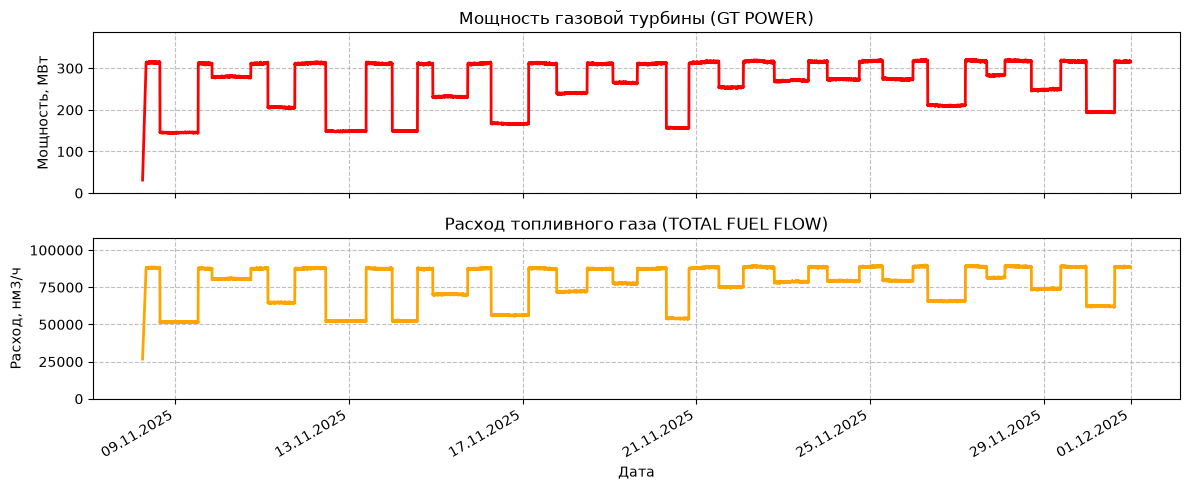

In [2]:
# 1.1.1. Настраиваем 2 графика друг под другом
fig,(ax1,ax2)=plt.subplots(2,1,figsize = (12,5), sharex = True) # sharex - связывает ось х двух графиков

# 1.1.2. График мощности (GT POWER)
ax1.plot(df['DATE'],df['GT POWER'], color = 'red', linewidth = 2)
ax1.set_title('Мощность газовой турбины (GT POWER)')
ax1.set_ylabel('Мощность, МВт')
ax1.set_xlabel('Дата')
ax1.set_ylim(0, df['GT POWER'].max() * 1.2)
ax1.grid(True, linestyle = '--', alpha = 0.8)

# 1.1.3. График расхода (TOTAL FUEL FLOW)
ax2.plot(df['DATE'],df['TOTAL FUEL FLOW'], color = 'orange', linewidth = 2)
ax2.set_title('Расход топливного газа (TOTAL FUEL FLOW)')
ax2.set_ylabel('Расход, нм3/ч')
ax2.set_xlabel('Дата')
ax2.set_ylim(0, df['TOTAL FUEL FLOW'].max() * 1.2)
ax2.grid(True, linestyle = '--', alpha = 0.8)

ax2.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%Y')) # изменяем отображение дат на графике
fig.autofmt_xdate()

plt.tight_layout()
plt.show()

1.2. Имитируем останов для модернизации компрессора с 19.11.2025 по 22.11.2025. Выбираем интервал останова и постепенно снижаем мощность и расход газа, потом повышаем. Изменением остальных параметров пренебрегаем. 

In [3]:
# 1.2.1. Задаем время начала и конца останова
start_shutdown = pd.to_datetime('2025-11-19 00:00:00')
stop_shutdown = start_shutdown+pd.Timedelta(hours = 2) # конец останова через 2 часа

# 1.2.2. Задаем время начала и конца пуска
start_startup=pd.to_datetime('2025-11-22 00:00:00')
stop_startup=start_startup+pd.Timedelta(hours = 1)     # конец пуска через 1 час

# 1.2.3. Создадим маску (True там, где даты попадает в интервал)
mask_shutdown = (df['DATE'] >= start_shutdown) & (df['DATE']<=stop_shutdown)
mask_standby = (df['DATE'] > stop_shutdown) & (df['DATE']<start_startup)
mask_startup = (df['DATE'] >= start_startup) & (df['DATE']<=stop_startup)

print(f"\nКол-во строк попадающих под останов: {mask_shutdown.sum()}")
print(f"\nКол-во строк попадающих в останове: {mask_standby.sum()}")
print(f"\nКол-во строк попадающих под пуск: {mask_startup.sum()}")


Кол-во строк попадающих под останов: 41

Кол-во строк попадающих в останове: 1399

Кол-во строк попадающих под пуск: 21


In [4]:
# 1.2.4. Берем последнее рабочее значение до начала останова
last_power = df[df['DATE'] < start_shutdown]['GT POWER'].iloc[-1]
last_fuel = df[df['DATE'] < start_shutdown]['TOTAL FUEL FLOW'].iloc[-1]

# 1.2.5. Создаем плавное затухание в останов от 1.0 до 0.0
n_shutdown = mask_shutdown.sum()
decay = np.linspace(1.0, 0.0, n_shutdown)

df.loc[mask_shutdown, 'GT POWER'] = last_power * decay
df.loc[mask_shutdown, 'TOTAL FUEL FLOW'] = last_fuel * decay

# 1.2.6. Создаем простой (мощность и расход = 0)
df.loc[mask_standby, 'GT POWER'] = 0.0
df.loc[mask_standby, 'TOTAL FUEL FLOW'] = 0.0

# 1.2.7. Берем первое рабочее значение после пуска
first_power = df[df['DATE'] > stop_startup]['GT POWER'].iloc[0]
first_fuel = df[df['DATE'] > stop_startup]['TOTAL FUEL FLOW'].iloc[0]

# 1.2.8. Создаем плавный рост от 0.0 до 1.0
n_startup = mask_startup.sum()
rise=np.linspace(0.0, 1.0, n_startup)

df.loc[mask_startup, 'GT POWER'] = first_power * rise
df.loc[mask_startup, 'TOTAL FUEL FLOW'] = first_fuel * rise

print("Данные изменены. Появились останов и пуск")

Данные изменены. Появились останов и пуск


1.3. Строим измененные тренды

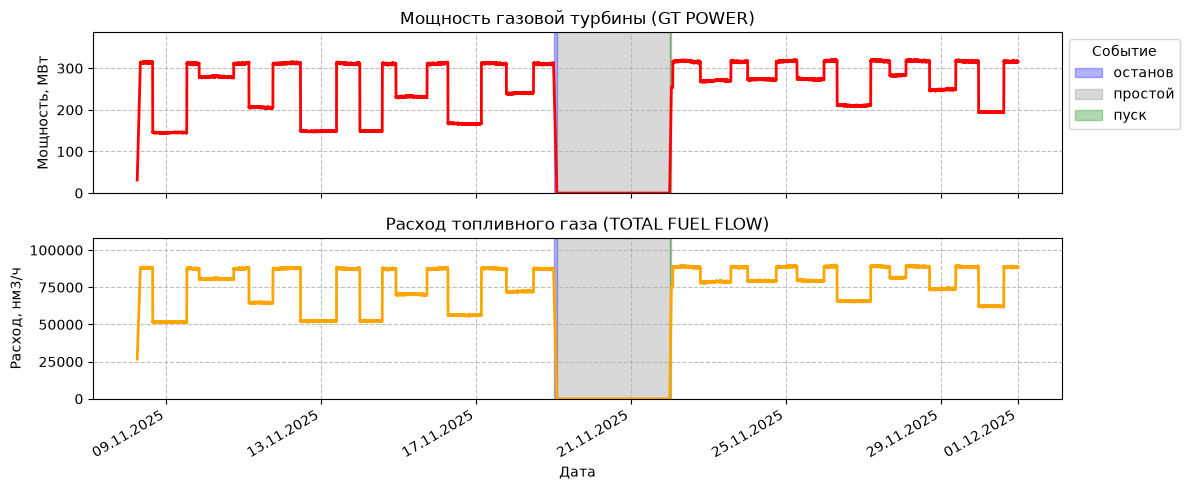

In [5]:
# 1.3.1. Настраиваем 2 графика друг под другом
fig,(ax1,ax2)=plt.subplots(2, 1,figsize=(12,5), sharex = True) # sharex - связывает ось х двух графиков

# 1.3.2. График мощности (GT POWER)
ax1.plot(df['DATE'],df['GT POWER'], color='red', linewidth=2)
ax1.set_title('Мощность газовой турбины (GT POWER)')
ax1.set_ylabel('Мощность, МВт')
ax1.set_xlabel('Дата')
ax1.set_ylim(0, df['GT POWER'].max()*1.2)
ax1.grid(True, linestyle='--', alpha=0.8)

# 1.3.3. График расхода (TOTAL FUEL FLOW)
ax2.plot(df['DATE'],df['TOTAL FUEL FLOW'], color = 'orange', linewidth=2)
ax2.set_title('Расход топливного газа (TOTAL FUEL FLOW)')
ax2.set_ylabel('Расход, нм3/ч')
ax2.set_xlabel('Дата')
ax2.set_ylim(0, df['TOTAL FUEL FLOW'].max()*1.2)
ax2.grid(True, linestyle='--', alpha=0.8)

# 1.3.4. Закрасим зоны (для наглядности)
for ax in [ax1,ax2]:
    ax.axvspan(start_shutdown, stop_shutdown, color='blue', alpha=0.3, label= 'останов')
    ax.axvspan(stop_shutdown, start_startup, color='gray', alpha=0.3, label= 'простой')
    ax.axvspan(start_startup, stop_startup, color='green', alpha=0.3, label= 'пуск')

ax2.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%Y'))           # изменяем отображение дат на графике
ax1.legend(title = 'Событие', bbox_to_anchor = (1,1), loc = 'upper left') # bbox_to_anchor=(координаты по осям х, у) для вынесения легенды за график
fig.autofmt_xdate()

plt.tight_layout()
plt.show()

2. Строим поправочные кривые

In [6]:
# 2.1. Фильтрация данных и подготовка. Для построения поправочных кривых выбираем номинальный режим работы: Nгту > 310, ВНА > 86.0 %
mask_nominal=(df['GT POWER'] > 310) & (df['IGV POSITION'] > 86.0)
df_nominal = df[mask_nominal].copy()
print(f"Всего точек: {len(df)}. Осталось точек: {len(df_nominal)}")

Всего точек: 10922. Осталось точек: 3707


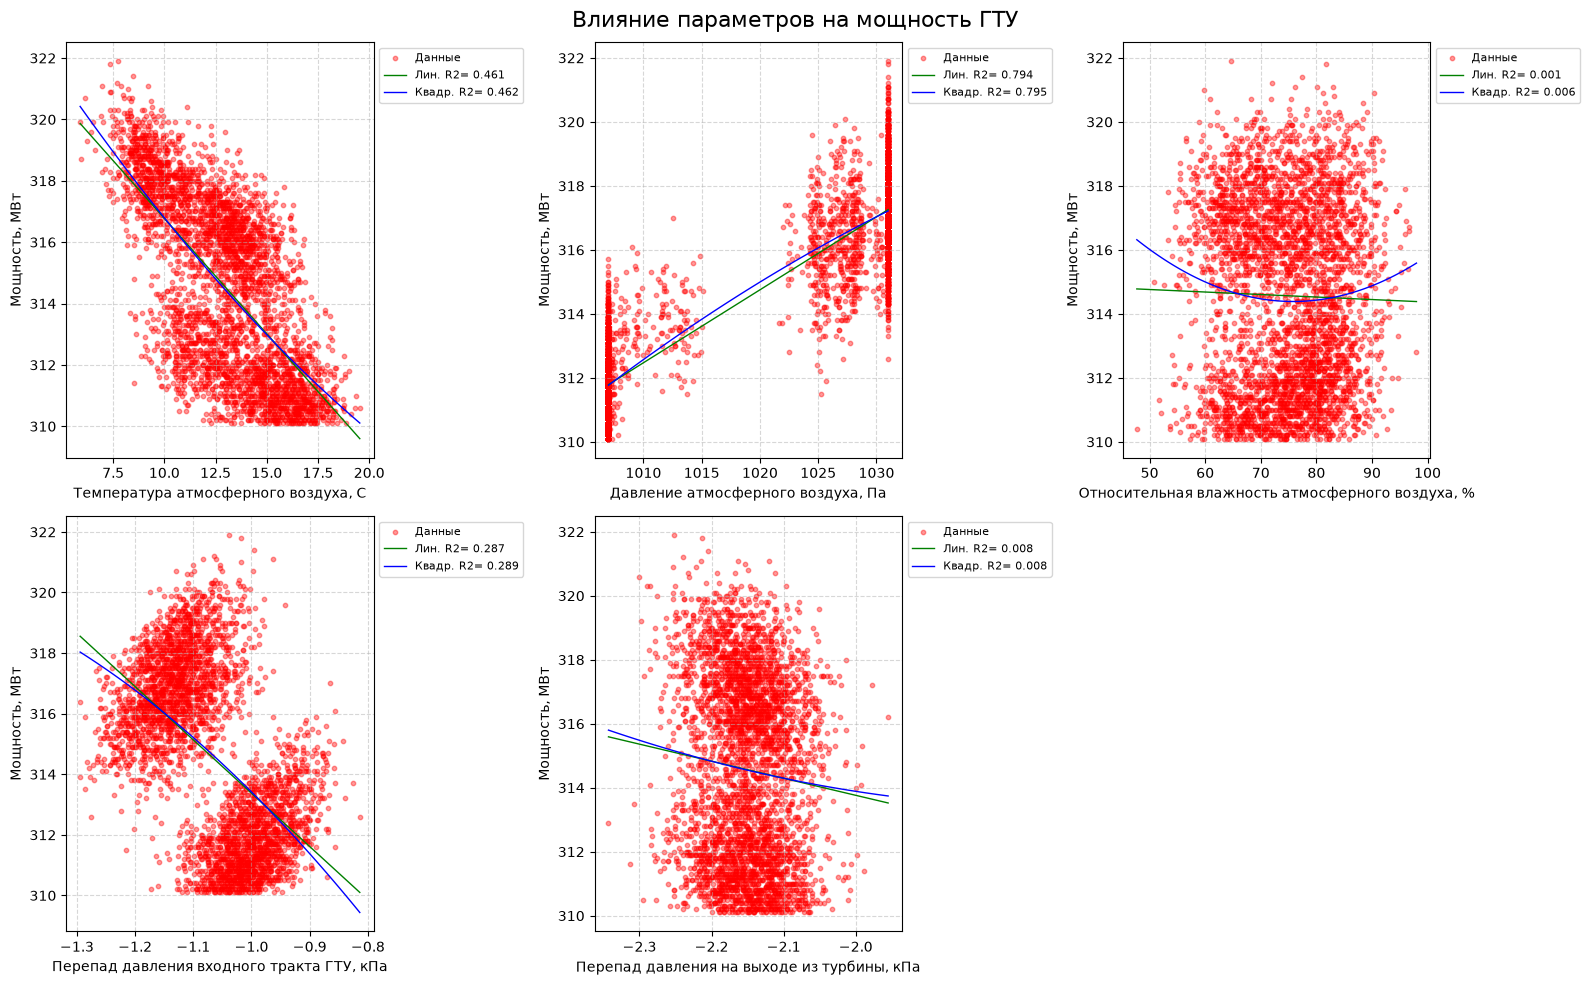

In [7]:
# 2.2. Строим сетку графиков для визуальной оценки
from sklearn.metrics import r2_score

params = [
    ('AMBIENT TEMPERATURE', 'Температура атмосферного воздуха, С'),
    ('BAROMETRIC PRESS', 'Давление атмосферного воздуха, Па'),
    ('AMBIENT HUMIDITY', 'Относительная влажность атмосферного воздуха, %'),
    ('INLET FILTER INSIDE PRESSURE', 'Перепад давления входного тракта ГТУ, кПа'),
    ('EXHAUST GAS DUCT PRESSURE', 'Перепад давления на выходе из турбины, кПа')
] # список параметров для анализа

fig, axes = plt.subplots(2, 3, figsize=(16,10)) # subplots - несколько графиков на одном "холсте"

axes=axes.flatten()                             # делаем как одномерный массив

for i, (col,label) in enumerate(params):        # enumerate(params) - функция, которая показывает параметр (i) и сам элемент списка
    ax = axes[i]
    
    ax.scatter(df_nominal[col],df_nominal['GT POWER'], alpha=0.4, color='red', s=10, label='Данные') # строим точечный график по реальным данным

#2.3. Проведем сравнение моделей линейной и квадратичной для описания тренда влияния параметров на мощность. Используем R-квадрат метрику
    
    # линейная модель (степень 1)
    z_lin = np.polyfit(df_nominal[col], df_nominal['GT POWER'], 1)
    p_lin = np.poly1d(z_lin)
    y_pred_lin = p_lin(df_nominal[col])
    r2_lin = r2_score(df_nominal['GT POWER'], y_pred_lin)

    # квадратичная модель (степень 2)
    z_quad = np.polyfit(df_nominal[col], df_nominal['GT POWER'], 2)
    p_quad = np.poly1d(z_quad)
    y_pred_quad = p_quad(df_nominal[col])
    r2_quad = r2_score(df_nominal['GT POWER'], y_pred_quad)

    # рисуем линии тренда (берем 100 точек)
    x_line=np.linspace(df_nominal[col].min(),df_nominal[col].max(), 100)
    ax.plot(x_line, p_lin(x_line), color='green', linewidth=1, label=f'Лин. R2= {r2_lin:.3f}')
    ax.plot(x_line, p_quad(x_line), color='blue', linewidth=1, label=f'Квадр. R2= {r2_quad:.3f}')
    
    # оформляем график
    ax.set_ylabel('Мощность, МВт')
    ax.set_xlabel(label)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(fontsize=8, bbox_to_anchor=(1,1), loc='upper left')
    
# убираем шестую ячейку
axes[5].axis('off')

plt.suptitle('Влияние параметров на мощность ГТУ', fontsize=16)
plt.tight_layout()
plt.show()



3. Определяем поправочные коэффициенты

In [8]:
# 3.1. Импорт необходимых инструментов
from sklearn.linear_model import LinearRegression

# 3.2. Указываем стандартные условия
T_std      = 15.0    # C
P_std      = 1013.25 # гектопаскали как в исходных данных
H_std      = 60      # %
dP_in_std  = 0.4     # кПа
dP_out_std = 0.4     # кПа

# 3.3 Создаем колонки, где вычтем стандартные значения
df_nominal['dT']    = df_nominal['AMBIENT TEMPERATURE']          - T_std
df_nominal['dP']    = df_nominal['BAROMETRIC PRESS']             - P_std
df_nominal['dH']    = df_nominal['AMBIENT HUMIDITY']             - H_std
df_nominal['dPin']  = df_nominal['INLET FILTER INSIDE PRESSURE'] - dP_in_std
df_nominal['dPout'] = df_nominal['EXHAUST GAS DUCT PRESSURE']    - dP_out_std

# 3.4. Находим номинальную мощность
P_nom = df_nominal['GT POWER'].mean()
print(f"номинальная мощность: {P_nom:.2f} МВт")

# 3.5. Создаем колонку с безразмерным коэффициентом
df_nominal['Power_coef'] = df_nominal['GT POWER']/P_nom

# 3.6. Указываем признаки (отклонения)
features_dev = ['dT','dP','dH','dPin','dPout']

# 3.7. Формируем матрицу [параметры][переменная]
X = df_nominal[features_dev]
Y = df_nominal['Power_coef']-1 # приращение коэффициента

# 3.8. Создаем пустую модель
model = LinearRegression()

# 3.9. Ищем коэффициенты по нашим данным
model.fit(X,Y)

print(f"Свободный член (intercept): {model.intercept_:.6f}")
print("\nКоэффициенты влияния на безразмерный коэффициент мощности:")
for name, coef in zip(features_dev, model.coef_):
    print(f"{name}: {coef:.6f}")



номинальная мощность: 314.57 МВт
Свободный член (intercept): -0.011671

Коэффициенты влияния на безразмерный коэффициент мощности:
dT: -0.001303
dP: 0.000888
dH: 0.000022
dPin: 0.049292
dPout: -0.029689


4. Расчет приведенной мощности

4.1. Считаем приведенную мощность для всего периода

In [9]:
# 4.1.1. Считаем отклонения от стандартных условий
dT    = df['AMBIENT TEMPERATURE']          - 15.0
dP    = df['BAROMETRIC PRESS']             - 1013.25
dH    = df['AMBIENT HUMIDITY']             - 60.0
dPin  = df['INLET FILTER INSIDE PRESSURE'] - 0.0
dPout = df['EXHAUST GAS DUCT PRESSURE']    - 0.0

# 4.1.2. Берем коэффициенты из обученной модели
k = dict(zip(features_dev, model.coef_))
delta = (k['dT']*dT+k['dP']*dP+k['dH']*dH+k['dPin']*dPin+k['dPout']*dPout)

# 4.1.3. Считаем приведенную мощность и выводим последние 10 строк
df['GT POWER CORR'] = df['GT POWER'] - P_nom*delta
print(df[['DATE','GT POWER','GT POWER CORR']].tail(10))
print(df[['GT POWER', 'GT POWER CORR']].describe())

                     DATE  GT POWER  GT POWER CORR
10912 2025-11-30 23:30:00     316.9     308.599091
10913 2025-11-30 23:33:00     316.1     308.625766
10914 2025-11-30 23:36:00     315.5     309.202877
10915 2025-11-30 23:39:00     317.3     308.553581
10916 2025-11-30 23:42:00     316.5     308.388376
10917 2025-11-30 23:45:00     314.2     308.458374
10918 2025-11-30 23:48:00     315.8     308.543677
10919 2025-11-30 23:51:00     317.5     308.899954
10920 2025-11-30 23:54:00     317.4     308.241182
10921 2025-11-30 23:57:00     316.3     308.157737
           GT POWER  GT POWER CORR
count  10922.000000   10922.000000
mean     225.695527     220.180838
std      103.867361     103.129315
min        0.000000     -10.191387
25%      166.400000     163.430245
50%      271.300000     261.618158
75%      311.900000     308.254448
max      321.900000     309.661266


4.2. Разбиваем на периоды до и после останова. Сравниваем медианные изменения мощностей

In [10]:
# 4.2.1. Определяем периоды
pre  = df['DATE'] <  pd.Timestamp('2025-11-19 00:00') # до останова
post = df['DATE'] >  pd.Timestamp('2025-11-22 01:00') # после пуска
mask_work = df['GT POWER'] > 100                      # отсекаем мощность < 100 МВт

# 4.2.2. Медиана (устойчива к выбросам)
print("\nМедиана")
for col in ['GT POWER', 'GT POWER CORR']:
    a = df.loc[pre  & mask_work, col].median()
    b = df.loc[post & mask_work, col].median()
    print(f"{col:10s}: до = {a:.2f}, после = {b:.2f}, Δ = {b-a:+.2f} МВт ({(b-a)/a*100:+.2f}%)")


Медиана
GT POWER  : до = 241.60, после = 281.40, Δ = +39.80 МВт (+16.47%)
GT POWER CORR: до = 237.65, после = 274.09, Δ = +36.44 МВт (+15.33%)


5. Расчет КПД осевого компрессора.

Для расчета будем использовать классический термодинамический расчет. Параметры воздуха будем определять с помощью инструмента CoolProp. Необходимо будет зафиксировать номинальный режим работы ГТУ и параметры воздуха перед компрессором.

5.1. Подготовка исходных данных

In [11]:
# 5.1.1. Номинальные параметры работы берем такие-же как в п. 2.1. 
df_nominal = df[(df['GT POWER']>310) & (df['IGV POSITION']> 86.0)].copy()

# 5.1.2. Находим давление перед компрессором
df_nominal['COMPRESSOR INLET AIR PRESSURE'] = (df_nominal['BAROMETRIC PRESS']*100+df_nominal['INLET FILTER INSIDE PRESSURE']*1000) # считаем давление в начале компрессора как разницу атмосферного давления и перепада на входной тракт. Переводим в Па.

# 5.1.3. Смотрим что получилось
df_nominal['COMBUSTOR SHELL PRESSURE'] = df_nominal['COMBUSTOR SHELL PRESSURE']*1000000                                            # Давление в камере сгорания в МПа. Переведем в Па

print(df_nominal[['COMPRESSOR INLET AIR TEMPERATURE', 'COMPRESSOR INLET AIR PRESSURE','COMPRESSOR OUTLET AIR TEMPERATURE','COMBUSTOR SHELL PRESSURE']].describe())

       COMPRESSOR INLET AIR TEMPERATURE  COMPRESSOR INLET AIR PRESSURE  \
count                       3707.000000                    3707.000000   
mean                          13.234230                  100850.858403   
std                            2.610445                    1063.598223   
min                            6.190000                   99527.700000   
25%                           11.170000                   99709.550000   
50%                           13.360000                  101393.900000   
75%                           15.215000                  101930.950000   
max                           19.840000                  102137.500000   

       COMPRESSOR OUTLET AIR TEMPERATURE  COMBUSTOR SHELL PRESSURE  
count                        3707.000000              3.707000e+03  
mean                          438.754454              1.895996e+06  
std                             6.137816              1.999566e+04  
min                           422.470000              1.8

5.2. Термодинамический расчет 

In [12]:

# 5.2.1. Импорт необходимых инструментов
import CoolProp
from CoolProp.CoolProp import PropsSI

# 5.2.1. Определяем параметры в начале цикла
T_nk = (df_nominal['COMPRESSOR INLET AIR TEMPERATURE'] + 273.15).values # Преобразование в numpy массив
P_nk = (df_nominal['COMPRESSOR INLET AIR PRESSURE']).values             
T_kk = (df_nominal['COMPRESSOR OUTLET AIR TEMPERATURE'] + 273.15).values
P_kk = (df_nominal['COMBUSTOR SHELL PRESSURE']).values


df_nominal['H_nk'] = PropsSI('H', 'T', T_nk, 'P' , P_nk, 'Air')         # Энтальпия воздуха перед компрессором
df_nominal['S_nk'] = PropsSI('S', 'T', T_nk, 'P' , P_nk, 'Air')         # Энтропия воздуха перед компрессором

# 5.2.2. Определяем параметры в конце теоретического цикла
S_nkt = (df_nominal['S_nk']).values
df_nominal['H_kkt'] = PropsSI('H', 'S', S_nkt, 'P' , P_kk, 'Air')       # Энтальпия воздуха за компрессором (теоретическая)

# 5.2.3. Определяем параметры в конце теоретического цикла
df_nominal['H_kk'] = PropsSI('H', 'T', T_kk, 'P' , P_kk, 'Air')         # Энтальпия воздуха за компрессором (фактическая)

# 5.2.4. Проверяем
print(df_nominal[['H_nk', 'H_kkt', 'H_kk']].describe().T)

        count           mean          std            min            25%  \
H_nk   3707.0  412599.493047  2627.221078  405510.977622  410520.204161   
H_kkt  3707.0  789461.621363  5982.982364  773305.833922  784719.142418   
H_kk   3707.0  852845.822860  6636.345986  835262.604481  847631.657400   

                 50%            75%            max  
H_nk   412723.094015  414591.245500  419247.631634  
H_kkt  789741.644099  794007.342733  804595.208076  
H_kk   853179.033624  857861.178896  871143.292590  


In [13]:
# 5.2.5. Определяем КПД
df_nominal_ETAk = (df_nominal['H_kkt'] - df_nominal["H_nk"]) / (df_nominal['H_kk'] - df_nominal["H_nk"])

print(f" среднее значение КПД компрессора = {df_nominal_ETAk.mean() * 100:.2f} %") 
print(f" медианное значение КПД компрессора = {df_nominal_ETAk.median() * 100:.2f} %")


 среднее значение КПД компрессора = 85.60 %
 медианное значение КПД компрессора = 85.60 %


In [14]:
# 5.2.6. Разбиваем на периоды. Смотрим, что в разные периоды КПД одинаковый
print("КПД до останова:")
print(f"  среднее  = {df_nominal_ETAk[pre].mean() * 100:.2f} %")
print(f"  медиана  = {df_nominal_ETAk[pre].median() * 100:.2f} %")

print("\nКПД после останова:")
print(f"  среднее  = {df_nominal_ETAk[post].mean() * 100:.2f} %")
print(f"  медиана  = {df_nominal_ETAk[post].median() * 100:.2f} %")

print(f"\nΔ медианы = {(df_nominal_ETAk[post].median() - df_nominal_ETAk[pre].median()) * 100:+.3f} %")

КПД до останова:
  среднее  = 85.60 %
  медиана  = 85.60 %

КПД после останова:
  среднее  = 85.61 %
  медиана  = 85.61 %

Δ медианы = +0.011 %


5.3. Принимаем КПД компрессора = 85,6 %. Во втором периоде увеличиваем КПД на 1,5 %.

In [15]:
# 5.3.1. Находим новую температуру на выходе из компрессора
ETAk_old = 0.856                                                   # средний КПД до модернизации
ETAk_new = 0.856 + 0.015                                           # прирост 1,5 процентных пункта
pre_nom  = df_nominal['DATE'] <  pd.Timestamp('2025-11-19 00:00')  # период до останова
post_nom = df_nominal['DATE'] >  pd.Timestamp('2025-11-22 01:00')  # период после останова

df_nominal['H_kk_new'] = df_nominal['H_kk']                                                                                                                   # оставляем параметры в первом периоде без изменений
df_nominal['T_kk_new'] = df_nominal['COMPRESSOR OUTLET AIR TEMPERATURE']

df_nominal.loc[post_nom, 'H_kk_new'] = (df_nominal.loc[post_nom, 'H_nk'] + (df_nominal.loc[post_nom, 'H_kkt'] - df_nominal.loc[post_nom, 'H_nk']) / ETAk_new) # изменяем параметры во втором периоде

P_kk_post = df_nominal.loc[post_nom,'COMBUSTOR SHELL PRESSURE'].values
df_nominal.loc[post_nom, 'T_kk_new'] = (PropsSI('T', 'H', df_nominal.loc[post_nom, 'H_kk_new'].values, 'P', P_kk_post, 'Air') - 273.15)  # в °C

# 5.3.2. Проверка
print("Первый период: H_kk == H_kk_new?", np.allclose(df_nominal.loc[pre_nom, 'H_kk'], df_nominal.loc[pre_nom, 'H_kk_new']))                                  # изменилась ли энтальпия за компрессором в первом периоде?

print(f"\nΔH во втором периоде = {df_nominal.loc[post_nom, 'H_kk_new'].mean() - df_nominal.loc[post_nom, 'H_kk'].mean():+.0f} Дж/кг")                         # изменение энтальпии за компрессором во втором периоде
print(f"ΔT во втором периоде = {df_nominal.loc[post_nom, 'T_kk_new'].mean() - df_nominal.loc[post_nom, 'COMPRESSOR OUTLET AIR TEMPERATURE'].mean():+.2f} °C") # изменение температуры за компрессором во втором периоде

Первый период: H_kk == H_kk_new? True

ΔH во втором периоде = -7516 Дж/кг
ΔT во втором периоде = -6.96 °C


6. Пересчет мощности ГТУ с учетом экономии работы компрессора

In [16]:
# 6.1. Находим разницу в работе компрессора до и после модернизации 
df_nominal['W_k_old'] = df_nominal['H_kk'] - df_nominal['H_nk']     # работа компрессора до модернизации
df_nominal['W_k_new'] = df_nominal['H_kk_new'] - df_nominal['H_nk'] # работа компрессора после модернизации

df_nominal['dW_k'] = df_nominal['W_k_old'] - df_nominal['W_k_new']  # количественное изменение работы компрессора
df_nominal['dW_rel'] = df_nominal['dW_k'] / df_nominal['W_k_old']   # изменение работы компрессора в долях

# 6.2. Находим новую приведенную мощность ГТУ
K_comp =  0.5 # доля работы компрессора в работе ГТУ

df_nominal['GT POWER CORR new'] = df_nominal['GT POWER CORR']                                                                           # по умолчанию старая
df_nominal.loc[post_nom, 'GT POWER CORR new']=(df_nominal.loc[post_nom, 'GT POWER CORR']*(1+df_nominal.loc[post_nom, 'dW_rel']*K_comp)) # во втором периоде изменяем

# 6.3. Проверка
print(f"в первом периоде: GT POWER CORR == GT POWER CORR new? {np.allclose(df_nominal.loc[pre_nom, 'GT POWER CORR'], df_nominal.loc[pre_nom, 'GT POWER CORR new'])}")

print(f"\nМощность ГТУ во втором периоде (старая): mean = {df_nominal.loc[post_nom, 'GT POWER CORR'].mean():.2f} МВт")
print(f"Мощность ГТУ во втором периоде (новая): mean = {df_nominal.loc[post_nom, 'GT POWER CORR new'].mean():.2f} МВт")
print(f"Прирост: {df_nominal.loc[post_nom, 'GT POWER CORR new'].mean() - df_nominal.loc[post_nom, 'GT POWER CORR'].mean():+.2f} МВт")
print(f"Прирост: {100*(df_nominal.loc[post_nom, 'GT POWER CORR new'].mean() / df_nominal.loc[post_nom, 'GT POWER CORR'].mean() - 1):+.2f} %")


в первом периоде: GT POWER CORR == GT POWER CORR new? True

Мощность ГТУ во втором периоде (старая): mean = 308.43 МВт
Мощность ГТУ во втором периоде (новая): mean = 311.07 МВт
Прирост: +2.64 МВт
Прирост: +0.86 %


In [17]:
# 6.4. Проведем t-test
from scipy import stats

pre_data = df_nominal.loc[pre_nom, 'GT POWER CORR']
post_old = df_nominal.loc[post_nom, 'GT POWER CORR']

t_stat, p_value = stats.ttest_ind(post_old, pre_data, equal_var=False)

print(f"t-тест (pre vs post-старая, БЕЗ модернизации):")
print(f"  Среднее pre:         {pre_data.mean():.2f} МВт")
print(f"  Среднее post-старая: {post_old.mean():.2f} МВт")
print(f"  Разница:             {post_old.mean() - pre_data.mean():+.2f} МВт")
print(f"  Разница:             {(post_old.mean() - pre_data.mean())/df_nominal['GT POWER'].mean()*100:+.2f} % от номинальной мощности")
print(f"  t-статистика:        {t_stat:.2f}")
print(f"  p-value:             {p_value:.4f}")

if p_value > 0.05:
    print("  → Разница НЕ значима (метод чистый, эффекта нет)")
else:
    print("  → Разница значима (есть систематическая ошибка)")

t-тест (pre vs post-старая, БЕЗ модернизации):
  Среднее pre:         308.43 МВт
  Среднее post-старая: 308.43 МВт
  Разница:             -0.00 МВт
  Разница:             -0.00 % от номинальной мощности
  t-статистика:        -0.25
  p-value:             0.8026
  → Разница НЕ значима (метод чистый, эффекта нет)


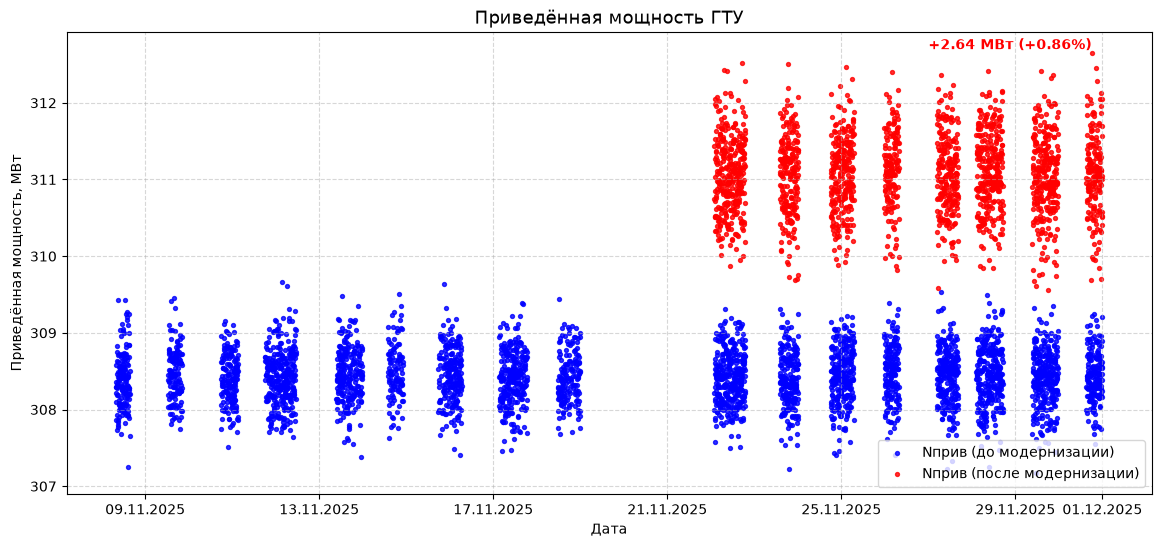

In [26]:
# 6.5. Строим графики изменения приведенной мощности во втором периоде.
fig, ax = plt.subplots(figsize=(14, 6))

dates_old = pd.concat([df_nominal.loc[pre_nom, 'DATE'], df_nominal.loc[post_nom, 'DATE']])                   # .concat объединяет два периода в один
power_old = pd.concat([df_nominal.loc[pre_nom, 'GT POWER CORR'], df_nominal.loc[post_nom, 'GT POWER CORR']]) 

ax.scatter(dates_old, power_old, color='blue', s=8, alpha=0.8, label='Nприв (до модернизации)')
ax.scatter(df_nominal.loc[post_nom, 'DATE'], df_nominal.loc[post_nom, 'GT POWER CORR new'], color='red', s=8, alpha=0.8, label='Nприв (после модернизации)')

ax.set_title('Приведённая мощность ГТУ', fontsize=13)
ax.set_xlabel('Дата')
ax.set_ylabel('Приведённая мощность, МВт')
ax.grid(True, linestyle='--', alpha=0.5)
ax.text(pd.Timestamp('2025-11-27'), 312.7, '+2.64 МВт (+0.86%)', color='red', fontsize=10, fontweight='bold')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%Y'))
ax.legend(loc='lower right', fontsize=10)

7. Считаем экономический эффект

In [19]:
# 7.1. Загружаем данные за 11.2025 с АТС "Энерго" https://www.atsenergo.ru/
df_prices=pd.read_csv('RSV_statistics_date_31102025_01112025.csv', sep=';', encoding='cp1251') # разделитель ";", меняем кодировку
df_prices=df_prices[['День','Индекс равновесных цен на покупку электроэнергии, руб./МВт·ч.']]  # оставляем только нужные столбцы
print(df_prices.head())

         День  Индекс равновесных цен на покупку электроэнергии, руб./МВт·ч.
0  31.10.2025                                            2175.39            
1  01.11.2025                                            2162.47            
2  02.11.2025                                            2122.15            
3  03.11.2025                                            2017.27            
4  04.11.2025                                            2034.73            


In [20]:
# 7.2. Объединяем таблицы по дням
df_nominal['date']=df_nominal['DATE'].dt.date                                                                    # дата без времени в основной таблице
df_prices['День'] = pd.to_datetime(df_prices['День'], format='%d.%m.%Y')
df_prices['date'] = df_prices['День'].dt.date
df_prices = df_prices.rename(columns={'Индекс равновесных цен на покупку электроэнергии, руб./МВт·ч.': 'price'}) # переименовываем столбец
df_nominal = df_nominal.merge(df_prices[['date', 'price']], on='date', how='left')

# 7.3. Проверка
print(df_nominal[['DATE', 'date', 'price']].head())
print("\nNaN в price:", df_nominal['price'].isna().sum())

                 DATE        date    price
0 2025-11-08 07:51:00  2025-11-08  2184.31
1 2025-11-08 07:54:00  2025-11-08  2184.31
2 2025-11-08 07:57:00  2025-11-08  2184.31
3 2025-11-08 08:00:00  2025-11-08  2184.31
4 2025-11-08 08:03:00  2025-11-08  2184.31

NaN в price: 0


In [21]:
# 7.4. Считаем разницу мощностей в каждой строке
df_nominal['dN'] = df_nominal['GT POWER CORR new'] - df_nominal['GT POWER CORR']
df_nominal['dE'] = df_nominal['dN'] * (3/60)                                     # энергия за строку (3 мин = 0.05 ч), МВт·ч 
df_nominal['dR'] = df_nominal['dE'] * df_nominal['price']                        # выручка за строку, руб

# 7.5. Сумма за период
total_revenue = df_nominal['dR'].sum()
print(f"Прирост выручки: {total_revenue/1e6:.2f} млн руб")

# 7.6. Определяем долю номинального режима от всего периода работы
diff_mode = len(df_nominal)/len(df)
print(f"Доля номинального режима: {diff_mode*100:.2f} %")

# 7.7. Приводим к году работы
hours_year = 8760
hours_idle = 1200 # принимаем, что 1200 часов в год турбина не работает
hours_work = hours_year - hours_idle
hours_nominal_work = hours_work * diff_mode
print(f"Часов работы в номинальном режиме в году: {hours_nominal_work:.2f} ч")

pre_nom  = df_nominal['DATE'] <  pd.Timestamp('2025-11-19 00:00') # обновляем периоды
post_nom = df_nominal['DATE'] >  pd.Timestamp('2025-11-22 01:00') # обновляем периоды

# 7.8. Считаем выручку
delta_N = df_nominal.loc[post_nom, 'GT POWER CORR new'].mean() - df_nominal.loc[post_nom, 'GT POWER CORR'].mean()                                         # средний прирост мощности
delta_Nper = 100*(df_nominal.loc[post_nom, 'GT POWER CORR new'].mean() / df_nominal.loc[post_nom, 'GT POWER CORR'].mean() - 1)                            # средний прирост мощности, %
delta_Npf = df_nominal.loc[post_nom, 'GT POWER CORR'].mean() - df_nominal.loc[pre_nom, 'GT POWER CORR'].mean()                                            # фоновая разница между периодами, МВт
delta_Npfper = (df_nominal.loc[post_nom, 'GT POWER CORR'].mean() - df_nominal.loc[pre_nom, 'GT POWER CORR'].mean()) / df_nominal['GT POWER'].mean() * 100 # фоновая разница между периодами, %
avg_price = df_nominal['price'].mean()                                                                                                                    # средняя цена за период
delta_energy_year = delta_N * hours_nominal_work                                                                                                          # МВт·ч/год
delta_revenue_year = delta_energy_year * avg_price                                                                                                        # руб

print(f"\nПрирост мощности: {delta_N:.2f} МВт")
print(f"Прирост мощности: {delta_Nper:.2f} %")
print(f"Фоновая разница: {delta_Npf:.2f} МВт")
print(f"Фоновая разница: {delta_Npfper:.2f} %")
print(f"Средняя цена:     {avg_price:.2f} руб/МВт·ч")
print(f"Энергия за год:   {delta_energy_year:.0f} МВт·ч")
print(f"Выручка за год:   {delta_revenue_year/1e6:.2f}  млн руб/год")

# 7.9. Посчитаем для разной доли работы компрессора от работы турбины
K_comp_values = [0.45, 0.50, 0.55]                                                                                 # доля от работы компрессора

dW_rel_mean = df_nominal.loc[post_nom, 'dW_rel'].mean()                                                            # средний относительный прирост работы компрессора
N_corr = df_nominal.loc[post_nom, 'GT POWER CORR'].mean()                                                          # базовая приведённая мощность (post)
results = []
for K in K_comp_values:
    N_corr_new = (df_nominal.loc[post_nom, 'GT POWER CORR'] * (1 + df_nominal.loc[post_nom, 'dW_rel'] * K)).mean() # новая мощность
    delta_N_k = N_corr_new - N_corr
    
    delta_energy_year = delta_N_k * hours_nominal_work     # годовая энергия
    delta_revenue_year = delta_energy_year * avg_price     # годовая выручка
    
    results.append({
        'K_comp': f"{K:.2f}",
        'Прирост мощности, МВт': round(delta_N_k, 2),
        'Прирост мощности, %': round(delta_N_k / N_corr * 100, 2),
        'Энергия за год, МВт·ч': round(delta_energy_year, 0),
        'Выручка за год, млн руб': round(delta_revenue_year/1e6, 2),
    })

df_results = pd.DataFrame(results)                         # вывод таблицы результатов
print("\nСравнение прироста и выручки при разной доле работы компрессора от работы турбины (K_comp)")
print(df_results.to_string(index=False))

Прирост выручки: 0.57 млн руб
Доля номинального режима: 33.94 %
Часов работы в номинальном режиме в году: 2565.91 ч

Прирост мощности: 2.64 МВт
Прирост мощности: 0.86 %
Фоновая разница: -0.00 МВт
Фоновая разница: -0.00 %
Средняя цена:     2209.86 руб/МВт·ч
Энергия за год:   6780 МВт·ч
Выручка за год:   14.98  млн руб/год

Сравнение прироста и выручки при разной доле работы компрессора от работы турбины (K_comp)
K_comp  Прирост мощности, МВт  Прирост мощности, %  Энергия за год, МВт·ч  Выручка за год, млн руб
  0.45                   2.38                 0.77                 6102.0                    13.48
  0.50                   2.64                 0.86                 6780.0                    14.98
  0.55                   2.91                 0.94                 7458.0                    16.48


ВЫВОДЫ: 

1. Фоновая разница между первым и вторым периодом отсутствует.
2. **Прирост располагаемой мощности: 2.38 - 2.91 МВт (+0.77 - 0.94 %)**
3. **Дополнительная выработка электроэнергии за год составит 6102-7458 МВт*ч или 13,48 - 16.48 млн руб.**

ОГРАНИЧЕНИЯ МОДЕЛИ:
1. Стоимость электроэнергии - дневной индекс РСВ первой ценовой зоны
2. Ноябрьские цены экстраполированы на год
3. Число часов простоя турбины в году принято 1200 
4. Доля работы компрессора от работы турбины принята 0,45-0,55